# 03 · The results, explained with numbers

**The question:** when Qwen2.5-7B reads a text word by word, does it behave differently on **factual** texts
(12: Wikipedia + Gutenberg non-fiction) than on **creative** texts (13: Harry Potter, joke books, Gutenberg fiction)?

At every noun or verb of a text we have two main measurements:
- **Surprisal**: how unexpected the real word was for the model (0 = it was certain of this word; higher = more surprised).
- **GloVe spread**: how different the model's 5 guesses for that word are in meaning (low = the 5 guesses are almost
  the same word, e.g. *said, replied, answered*; high = 5 unrelated words).

Every figure below puts **factual texts and creative texts in separate panels**, and every figure is followed by a
**table with the exact numbers**. Reads the saved results of notebooks 01 and 02 (no model run, no clustering run).

**Three numbers used throughout**
- **median**: the middle value (half the words/texts are above it, half below).
- **pairs in order**: take every factual text and every creative text (12 × 13 = 156 pairs). In how many of the pairs
  is the factual text on the expected side? **100% = this one number alone separates the two kinds perfectly;
  50% = no better than a coin flip.**
- **p-value** (Mann-Whitney test): the chance of seeing a difference this big if the kind of text didn't matter.
  Below 0.05 = unlikely to be luck.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
warnings.filterwarnings("ignore")

# walk up from the notebook's folder until we find the repo root (the folder holding lca_core.py)
ROOT = Path.cwd()
while not (ROOT / "lca_core.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("lca_core.py not found in this folder or any parent folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import mannwhitneyu

from lca_core import add_glove_spread, kind

HERE = ROOT / "src" / "note_books" / "Qwen7B"
RESULTS = HERE / "results"
FIG_DIR = RESULTS / "figures_explained"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FACTUAL_COLOR = "#2a78d6"     # validated pair (dataviz palette check: all pass, incl. colour-blind separation)
CREATIVE_COLOR = "#eb6834"
COLORS = {"factual": FACTUAL_COLOR, "creative": CREATIVE_COLOR}
INK = "#0b0b0b"
INK_SOFT = "#52514e"
GRID = "#e4e3df"
ZONE = "#f1f0ec"
KINDS = ["factual", "creative"]


def short(name):
    for long_prefix, short_prefix in [("factual_wiki_", "wiki:"), ("factual_gut_", "gut:"),
                                      ("creative_gut_", "gut:"), ("creative_", "")]:
        name = name.replace(long_prefix, short_prefix)
    return name


def clean_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_SOFT, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name, tries=3):
    # OneDrive sometimes refuses the first overwrite of a synced file (OSError 22): remove it and retry
    path = FIG_DIR / name
    for attempt in range(tries):
        try:
            fig.savefig(path, dpi=110, bbox_inches="tight")
            return
        except OSError:
            if attempt == tries - 1:
                print(f"could not save {name} (file locked?)")
                return
            path.unlink(missing_ok=True)


text_names = sorted(path.stem for path in (RESULTS / "words").glob("*.csv"))
words = {name: pd.read_csv(RESULTS / "words" / f"{name}.csv") for name in text_names}
words = add_glove_spread({"Qwen_Qwen2.5-7B-Instruct": words})["Qwen_Qwen2.5-7B-Instruct"]
names_of = {k: [n for n in text_names if kind(n) == k] for k in KINDS}
print({k: len(v) for k, v in names_of.items()})

{'factual': 12, 'creative': 13}


## 1. One factual and one creative text, side by side
Each line is one text read from start to end; every point is one noun or verb. Same scale left and right.
The box in each panel gives that text's numbers.

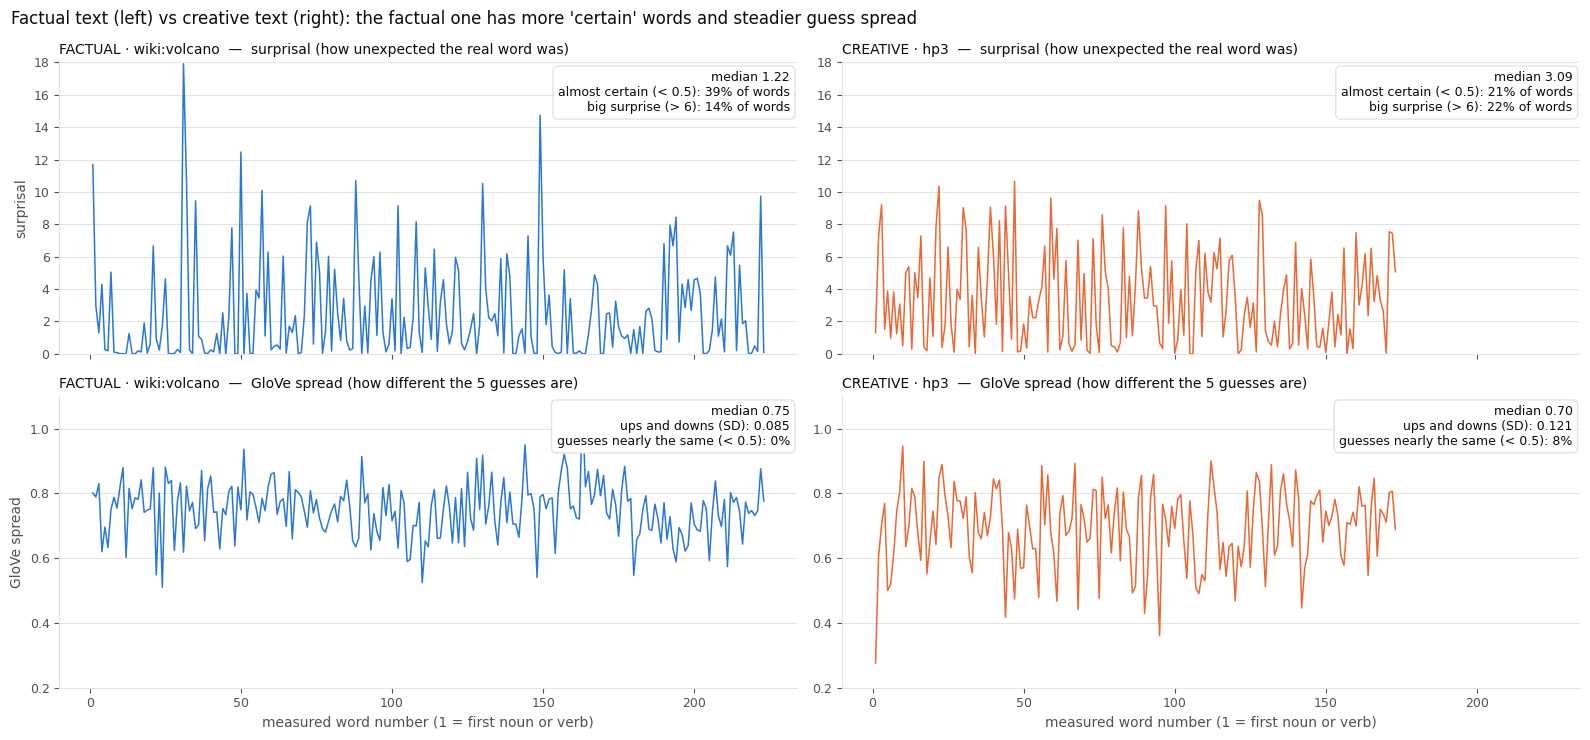

In [2]:
EXAMPLES = {"factual": "factual_wiki_volcano", "creative": "creative_hp3"}
PANELS = [("surprisal", "surprisal (how unexpected the real word was)", (0, 18)),
          ("glove_mean", "GloVe spread (how different the 5 guesses are)", (0.2, 1.1))]


def describe(values, column):
    if column == "surprisal":
        return (f"median {np.median(values):.2f}\n"
                f"almost certain (< 0.5): {(values < 0.5).mean():.0%} of words\n"
                f"big surprise (> 6): {(values > 6).mean():.0%} of words")
    return (f"median {np.median(values):.2f}\n"
            f"ups and downs (SD): {values.std():.3f}\n"
            f"guesses nearly the same (< 0.5): {(values < 0.5).mean():.0%}")


fig, axes = plt.subplots(len(PANELS), 2, figsize=(16, 7.5), sharex=True)
for row, (column, title, limits) in enumerate(PANELS):
    for col, kind_name in enumerate(KINDS):
        ax = axes[row, col]
        values = words[EXAMPLES[kind_name]][column].dropna().to_numpy()
        ax.plot(np.arange(1, len(values) + 1), values, color=COLORS[kind_name], lw=1.1)
        ax.set_ylim(*limits)
        ax.text(0.99, 0.97, describe(values, column), transform=ax.transAxes, ha="right", va="top", fontsize=9,
                color=INK, bbox={"boxstyle": "round,pad=0.4", "fc": "white", "ec": GRID})
        ax.set_title(f"{kind_name.upper()} · {short(EXAMPLES[kind_name])}  —  {title}", loc="left", fontsize=10,
                     color=INK)
        clean_axes(ax)
    axes[row, 0].set_ylabel(column.replace("glove_mean", "GloVe spread"), color=INK_SOFT)
for ax in axes[-1]:
    ax.set_xlabel("measured word number (1 = first noun or verb)", color=INK_SOFT)
fig.suptitle("Factual text (left) vs creative text (right): the factual one has more 'certain' words and steadier "
             "guess spread", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
save(fig, "1_example_texts.png")
plt.show()

## 2. All measured words of each kind: where do the values fall?
Every measured word of all 12 factual texts (left) and all 13 creative texts (right), counted by value. The grey
zones and the percentages above them show how many words fall into each range.

**How to read it:** bar height = share of words with that value. Compare the percentages left vs right.

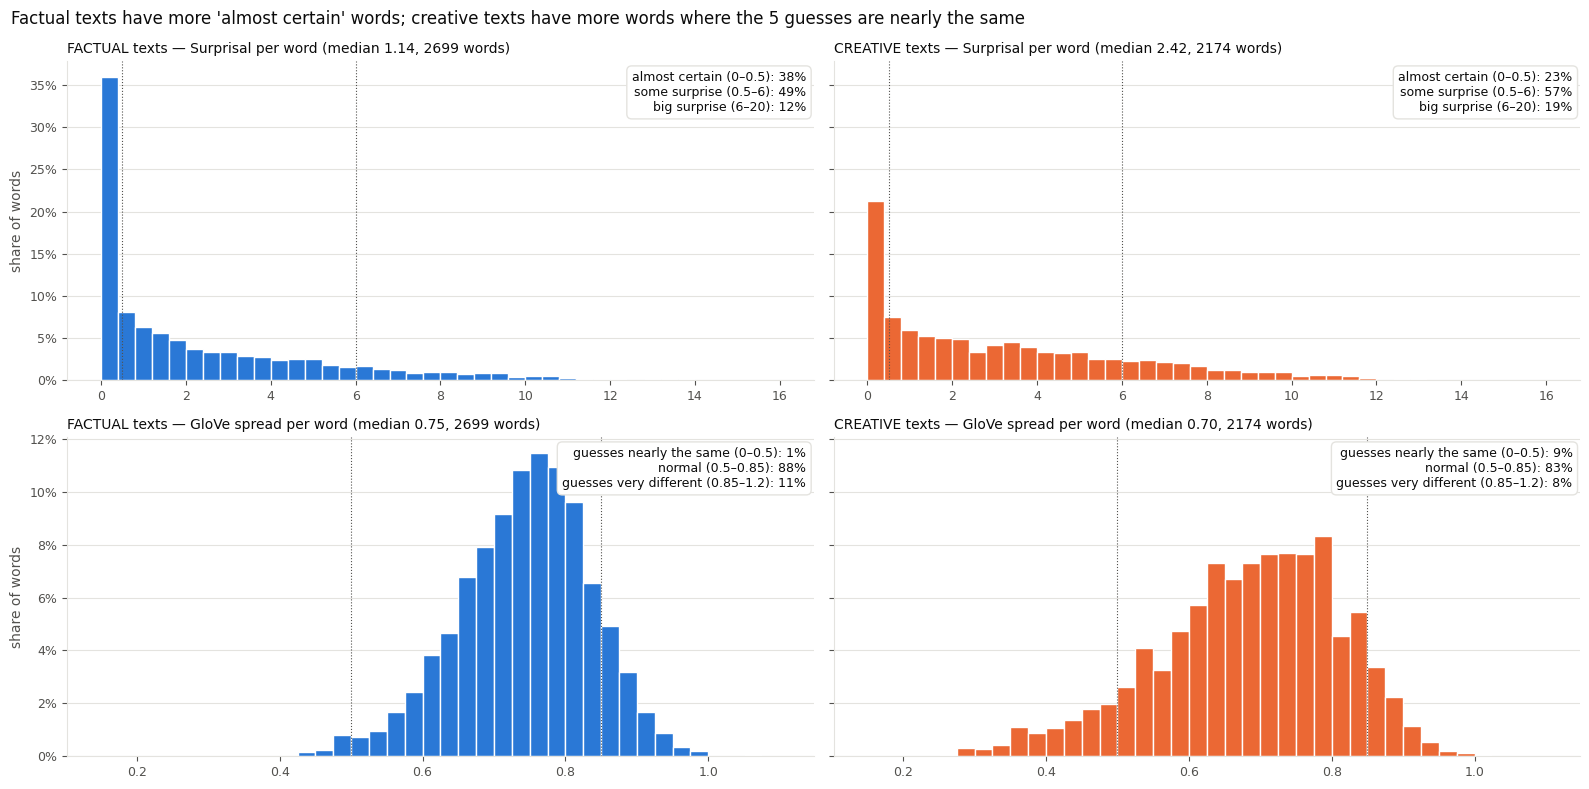

In [3]:
ZONES = {
    "surprisal": [(0, 0.5, "almost certain"), (0.5, 6, "some surprise"), (6, 20, "big surprise")],
    "glove_mean": [(0, 0.5, "guesses nearly the same"), (0.5, 0.85, "normal"), (0.85, 1.2, "guesses very different")],
}
BINS = {"surprisal": np.linspace(0, 16, 41), "glove_mean": np.linspace(0.15, 1.1, 39)}
TITLES = {"surprisal": "Surprisal per word", "glove_mean": "GloVe spread per word"}

zone_rows = []
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharey="row")
for row, column in enumerate(["surprisal", "glove_mean"]):
    for col, kind_name in enumerate(KINDS):
        ax = axes[row, col]
        values = np.concatenate([words[n][column].dropna().to_numpy() for n in names_of[kind_name]])
        weights = np.full(len(values), 1 / len(values))
        ax.hist(values, bins=BINS[column], weights=weights, color=COLORS[kind_name], edgecolor="white", lw=1)
        box_lines = []
        for low, high, label in ZONES[column]:
            share = ((values >= low) & (values < high)).mean()
            if low > 0:
                ax.axvline(low, color=INK_SOFT, lw=0.8, ls=":")
            box_lines.append(f"{label} ({low}–{high}): {share:.0%}")
            zone_rows.append({"measure": TITLES[column], "kind": kind_name, "range": f"{label} ({low}–{high})",
                              "share of words": share})
        ax.text(0.99, 0.97, "\n".join(box_lines), transform=ax.transAxes, ha="right", va="top", fontsize=9,
                color=INK, bbox={"boxstyle": "round,pad=0.4", "fc": "white", "ec": GRID})
        ax.set_title(f"{kind_name.upper()} texts — {TITLES[column]} "
                     f"(median {np.median(values):.2f}, {len(values)} words)", loc="left", fontsize=10, color=INK)
        clean_axes(ax)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    axes[row, 0].set_ylabel("share of words", color=INK_SOFT)
fig.suptitle("Factual texts have more 'almost certain' words; creative texts have more words where the 5 guesses "
             "are nearly the same", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
save(fig, "2_where_values_fall.png")
plt.show()

zones = pd.DataFrame(zone_rows).pivot_table(index=["measure", "range"], columns="kind", values="share of words",
                                            sort=False)[KINDS]
zones.style.format("{:.1%}")

## 3. Text by text: the numbers that separate the two kinds
Each dot is **one text**: its value of a simple number computed from its curve. Factual texts on the top row,
creative on the bottom. The short vertical line and the number next to it = the **median text** of that kind.
Under each title: how cleanly that number alone separates the kinds (**pairs in order**) and the **p-value**.

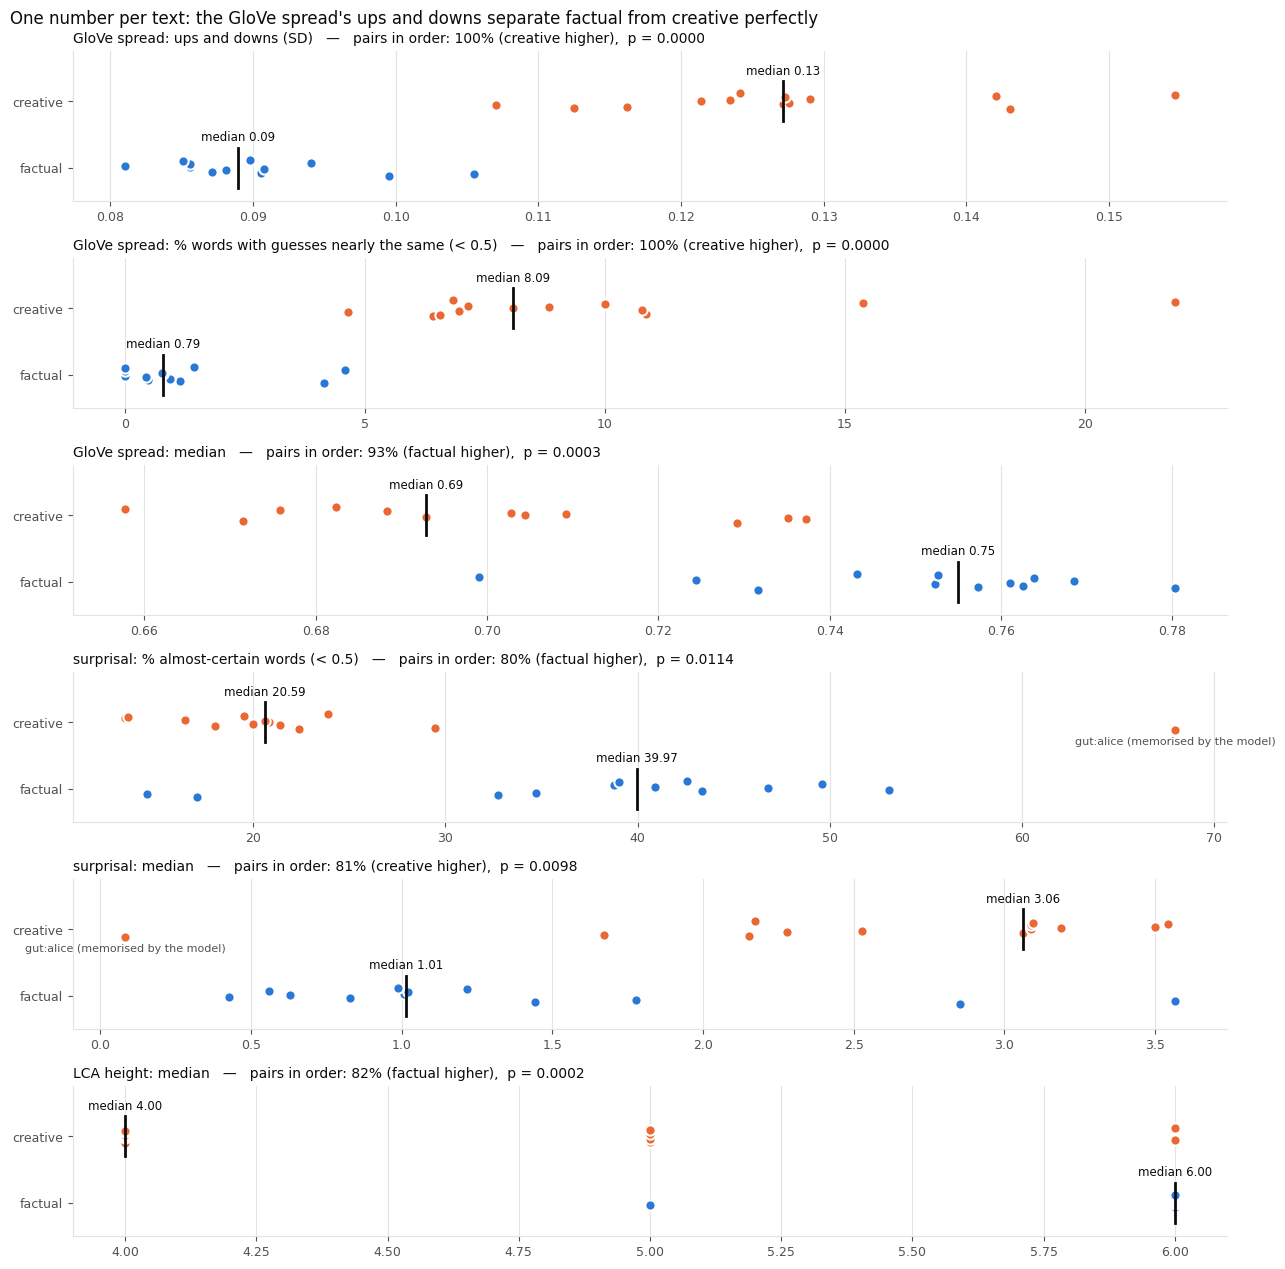

number,factual median,creative median,who is higher,pairs in order,p-value
GloVe spread: ups and downs (SD),0.089,0.127,creative higher,100%,0.0000
GloVe spread: % words with guesses nearly the same (< 0.5),0.786,8.092,creative higher,100%,0.0000
GloVe spread: median,0.755,0.693,factual higher,93%,0.0003
LCA height: median,6.000,4.000,factual higher,82%,0.0002
surprisal: median,1.013,3.063,creative higher,81%,0.0098
surprisal: % almost-certain words (< 0.5),39.970,20.588,factual higher,80%,0.0114


In [4]:
MEASURES = {
    "GloVe spread: ups and downs (SD)": lambda d: d["glove_mean"].dropna().std(),
    "GloVe spread: % words with guesses nearly the same (< 0.5)": lambda d: (d["glove_mean"].dropna() < 0.5).mean() * 100,
    "GloVe spread: median": lambda d: d["glove_mean"].dropna().median(),
    "surprisal: % almost-certain words (< 0.5)": lambda d: (d["surprisal"] < 0.5).mean() * 100,
    "surprisal: median": lambda d: d["surprisal"].median(),
    "LCA height: median": lambda d: d["lca_height"].median(),
}

per_text = pd.DataFrame({"text": [short(n) for n in text_names], "kind": [kind(n) for n in text_names]})
for title, function in MEASURES.items():
    per_text[title] = [function(words[n]) for n in text_names]


def separation(title):
    factual = per_text[per_text["kind"] == "factual"][title].to_numpy()
    creative = per_text[per_text["kind"] == "creative"][title].to_numpy()
    factual_higher = (factual[:, None] > creative[None, :]).mean()
    factual_lower = (factual[:, None] < creative[None, :]).mean()
    p_value = mannwhitneyu(factual, creative).pvalue
    direction = "factual higher" if factual_higher >= factual_lower else "creative higher"
    return max(factual_higher, factual_lower), p_value, direction, np.median(factual), np.median(creative)


fig, axes = plt.subplots(len(MEASURES), 1, figsize=(13, 2.15 * len(MEASURES)))
summary_rows = []
for ax, title in zip(axes, MEASURES):
    in_order, p_value, direction, factual_median, creative_median = separation(title)
    for row, kind_name in enumerate(KINDS):
        values = per_text[per_text["kind"] == kind_name][title].to_numpy()
        ax.scatter(values, np.full(len(values), row) + np.linspace(-0.12, 0.12, len(values)), s=55,
                   color=COLORS[kind_name], edgecolor="white", linewidth=1.5, zorder=3)
        median = np.median(values)
        ax.plot([median, median], [row - 0.3, row + 0.3], color=INK, lw=2, zorder=4)
        ax.text(median, row + 0.36, f"median {median:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK)
    if title.startswith("surprisal"):
        alice = per_text[per_text["text"] == "gut:alice"][title].iloc[0]
        ax.annotate("gut:alice (memorised by the model)", (alice, 1), xytext=(0, -16), textcoords="offset points",
                    ha="center", fontsize=8, color=INK_SOFT)
    ax.set_yticks([0, 1], ["factual", "creative"])
    ax.set_ylim(-0.5, 1.75)
    ax.set_title(f"{title}   —   pairs in order: {in_order:.0%} ({direction}),  p = {p_value:.4f}",
                 loc="left", fontsize=10, color=INK)
    clean_axes(ax, grid_axis="x")
    summary_rows.append({"number": title, "factual median": factual_median, "creative median": creative_median,
                         "who is higher": direction, "pairs in order": in_order, "p-value": p_value})
fig.suptitle("One number per text: the GloVe spread's ups and downs separate factual from creative perfectly",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
save(fig, "3_numbers_per_text.png")
plt.show()

summary = pd.DataFrame(summary_rows).sort_values("pairs in order", ascending=False)
summary.style.format({"factual median": "{:.3f}", "creative median": "{:.3f}", "pairs in order": "{:.0%}",
                      "p-value": "{:.4f}"}).hide(axis="index")

## 4. The clustering: how many texts did each method sort correctly?
Notebook 02 clustered the texts by their **whole curves** (without being told which texts are factual). For the best
run of each measurement: each cluster is named after the kind most of its texts have, and a text counts as
**sorted correctly** if it landed in its own kind's cluster (DBSCAN's "no cluster" texts count as not sorted).
Blue bars: factual texts sorted correctly (out of 12); orange bars: creative (out of 13).

Note **Rényi**: DBSCAN put 12 creative texts in one group and left **every factual text in no cluster**, so its
factual bar is 0/12. A clustering score (ARI) can look moderate even when one kind is not grouped at all, which is why
the counts are shown here.

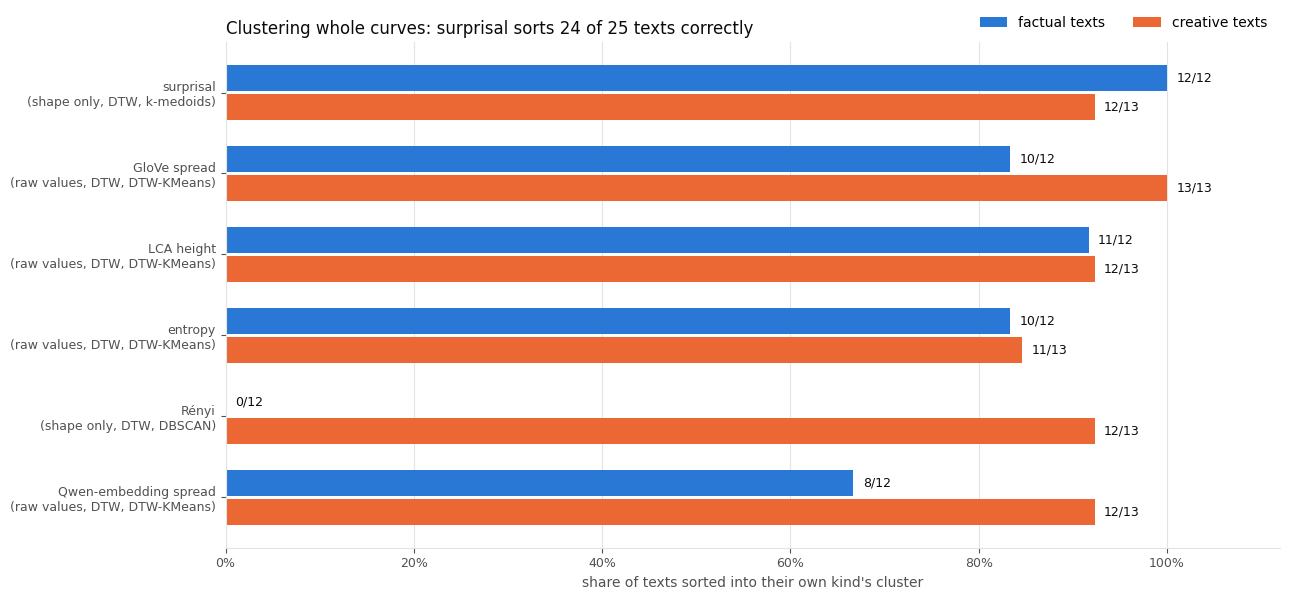

measurement,how,ARI,factual correct,factual total,creative correct,creative total,all correct
surprisal,"shape only, DTW, k-medoids",0.84,12,12,12,13,24
GloVe spread,"raw values, DTW, DTW-KMeans",0.69,10,12,13,13,23
LCA height,"raw values, DTW, DTW-KMeans",0.69,11,12,12,13,23
entropy,"raw values, DTW, DTW-KMeans",0.44,10,12,11,13,21
Rényi,"shape only, DTW, DBSCAN",0.33,0,12,12,13,12
Qwen-embedding spread,"raw values, DTW, DTW-KMeans",0.33,8,12,12,13,20


In [5]:
runs = pd.read_csv(RESULTS / "clustering_runs.csv")
assignments = pd.read_csv(RESULTS / "cluster_assignments.csv")
word_runs = runs[runs["axis"] == "measured word"]
best_runs = word_runs.sort_values("ARI", ascending=False).groupby("metric", as_index=False).first()
best_runs = best_runs.sort_values("ARI", ascending=False)

score_rows = []
for _, run in best_runs.iterrows():
    chosen = assignments[(assignments["axis"] == run["axis"]) & (assignments["metric"] == run["metric"]) &
                         (assignments["scaling"] == run["scaling"]) & (assignments["distance"] == run["distance"]) &
                         (assignments["method"] == run["method"])].copy()
    chosen["kind"] = chosen["text"].map(kind)
    cluster_kind = {}
    for cluster, group in chosen.groupby("cluster"):
        if cluster != -1:
            cluster_kind[cluster] = group["kind"].mode()[0]
    chosen["correct"] = [cluster_kind.get(c) == k for c, k in zip(chosen["cluster"], chosen["kind"])]
    row = {"measurement": run["metric"],
           "how": f"{'shape only' if run['scaling'] == 'standardised' else 'raw values'}, {run['distance']}, {run['method']}",
           "ARI": run["ARI"]}
    for kind_name in KINDS:
        members = chosen[chosen["kind"] == kind_name]
        row[f"{kind_name} correct"] = int(members["correct"].sum())
        row[f"{kind_name} total"] = len(members)
    row["all correct"] = row["factual correct"] + row["creative correct"]
    score_rows.append(row)
scores = pd.DataFrame(score_rows)

fig, ax = plt.subplots(figsize=(13, 0.75 * len(scores) + 1.6))
y = np.arange(len(scores))[::-1]
height = 0.36
for offset, kind_name in [(height / 2, "factual"), (-height / 2, "creative")]:
    shares = scores[f"{kind_name} correct"] / scores[f"{kind_name} total"]
    ax.barh(y + offset, shares, height=height - 0.04, color=COLORS[kind_name], label=f"{kind_name} texts")
    for position, share, correct, total in zip(y + offset, shares, scores[f"{kind_name} correct"],
                                               scores[f"{kind_name} total"]):
        ax.text(share + 0.01, position, f"{correct}/{total}", va="center", fontsize=9, color=INK)
labels = [f"{m}\n({h})" for m, h in zip(scores["measurement"], scores["how"])]
ax.set_yticks(y, labels, fontsize=9)
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("share of texts sorted into their own kind's cluster", color=INK_SOFT)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
clean_axes(ax, grid_axis="x")
ax.set_title("Clustering whole curves: surprisal sorts 24 of 25 texts correctly", loc="left", fontsize=12, color=INK)
fig.tight_layout()
save(fig, "4_clustering_correct.png")
plt.show()

scores.style.format({"ARI": "{:.2f}"}).hide(axis="index")

## 5. Every text's numbers
The full table behind section 3, one row per text.

In [6]:
per_text.sort_values(["kind", "text"], ascending=[False, True]).round(3).style.hide(axis="index")

text,kind,GloVe spread: ups and downs (SD),GloVe spread: % words with guesses nearly the same (< 0.5),GloVe spread: median,surprisal: % almost-certain words (< 0.5),surprisal: median,LCA height: median
gut:candle,factual,0.100000,4.145000,0.732000,17.098000,2.854000,6.000000
gut:origin_species,factual,0.105000,1.149000,0.780000,32.759000,1.442000,6.000000
gut:outline_science,factual,0.091000,0.467000,0.757000,14.486000,3.566000,6.000000
gut:relativity,factual,0.087000,0.926000,0.763000,34.722000,1.777000,6.000000
wiki:black_hole,factual,0.088000,0.429000,0.752000,43.348000,0.827000,5.000000
wiki:copper,factual,0.091000,0.000000,0.761000,53.086000,0.427000,6.000000
wiki:mitochondrion,factual,0.086000,0.800000,0.769000,46.800000,0.629000,6.000000
wiki:photosynthesis,factual,0.081000,0.772000,0.724000,40.927000,1.007000,6.000000
wiki:plate_tectonics,factual,0.086000,0.000000,0.764000,38.776000,1.020000,6.000000
wiki:vaccine,factual,0.094000,4.583000,0.699000,49.583000,0.561000,6.000000


## 6. What the numbers say
1. **The clearest difference is how much the model's 5 guesses vary in meaning from word to word (GloVe spread).**
   Every creative text has bigger ups and downs than every factual text (100% of pairs in order). Creative texts have
   many more words where the 5 guesses are nearly the same (about 8% of words vs under 1%): moments where the story
   makes the next word's *kind* obvious ("he *said / replied / answered*"), followed by open moments.
   Factual texts keep the guesses at a steady, medium-to-high variety.
2. **Surprisal:** factual texts have about **twice as many almost-certain words** (40% vs 21% of words) and a lower
   median surprisal; creative texts sit in the middle more often and have more big surprises. Clustering the whole
   surprisal curves (shape only) sorts **24 of 25 texts** correctly.
3. **LCA height** (WordNet) is higher for factual texts (median 6 vs 4), but part of that is that creative texts use
   more verbs, which sit lower in WordNet.

**Caveats:** 25 texts is a small sample. GloVe spread is partly affected by word rarity (factual texts use rarer
words), which was not corrected here (raw values, by choice). *Alice in Wonderland* has very low surprisal
because the model has most likely memorised it.